# 00 · 환경과 데이터 검증

국내 ETF 20종의 고정 원자료, 실행환경, 연도별 학습·검정 경계를 먼저 검증한다. 원자료를 다시 다운로드하지 않는다. 2020은 학습 이력 1년의 파일럿이고 2026은 10월 2일까지의 부분·비블라인드 구간이다. 다음 문서는 01 계산, 02 가설과 한계다.

이 연구는 잔차 제곱의 사후 분산 검정이며 가격 상승 방향·거래 수익률을 평가하지 않는다.

## 0. 환경 · 경로 assert (숨은 상태 차단)

In [1]:
# 운영체제 환경 변수 접근
import os

# BLAS/OpenMP 스레드를 1개로 고정 — numpy 를 import 하기 전에 해야 효과가 있다 (PROTOCOL_LOCK L9, CLI 와 같은 조건)
for _k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    # 각 스레드 변수를 "1" 로 설정
    os.environ[_k] = "1"

# 인터프리터·모듈 검색 경로
import sys

# 경로 처리
from pathlib import Path

# numpy 가 이 셀보다 먼저 로드됐다면 스레드 설정이 늦은 것이므로 멈춘다
assert "numpy" not in sys.modules, "numpy 가 이미 import 됨 — 커널을 새로 시작하고 첫 셀부터 실행할 것"
# 저장소 루트: 현재 폴더에서 위로 올라가며 T12 설정 파일과 src/r2h 가 함께 있는 첫 폴더
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "t12_annual_expanding_v2.json").exists() and (p / "src" / "r2h").is_dir())
# 이 저장소의 src 를 검색 경로 맨 앞에 넣는다 (.venv 의 editable 설치 = 다른 트리의 src 를 가린다)
sys.path.insert(0, str(ROOT / "src"))
# 연구 패키지
import r2h

# r2h 가 반드시 이 저장소의 src 에서 왔는지 확인 (원본 트리 src 를 잡으면 원본 outputs 를 덮어쓸 위험)
assert Path(r2h.__file__).resolve().is_relative_to((ROOT / "src").resolve()), r2h.__file__
# T12 설정 모듈 (REPO_ROOT 는 r2h 파일 위치 기준으로 정해진다)
from r2h.annual_expanding import config as t12config

# 출력 경로의 기준(REPO_ROOT)도 이 저장소여야 한다
assert t12config.REPO_ROOT.resolve() == ROOT.resolve(), (t12config.REPO_ROOT, ROOT)
# 결과 확인용 출력
print("ROOT          =", ROOT)
# r2h 위치 출력
print("r2h.__file__  =", r2h.__file__)
# 인터프리터 위치 출력
print("sys.executable=", sys.executable)

ROOT          = /home/sieg/projects-wsl/hongik_univ_26_2/SA/1016/R2H_T12_Final
r2h.__file__  = /home/sieg/projects-wsl/hongik_univ_26_2/SA/1016/R2H_T12_Final/src/r2h/__init__.py
sys.executable= /home/sieg/projects-wsl/hongik_univ_26_2/SA/1012_Annual_SVR–GARCH-CUSUM/R2H/.venv/bin/python


**다음 계산: 설치된 패키지 버전 조회 (uv pip freeze 대신 표준 라이브러리)**

위 단계의 출력과 구분해 입력·설정·결과를 아래 실행 셀에 남긴다. 오류가 나면 다음 셀로 진행하지 않는다.

In [2]:
# 설치된 패키지 버전 조회 (uv pip freeze 대신 표준 라이브러리)
import importlib.metadata as md

# 플랫폼 정보 (Python 버전)
import platform

# 기준 run(seq_golden) 의 실행 환경 — run_manifest.json 의 environment 와 같아야 같은 수치 경로를 보장할 수 있다
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scikit-learn": "1.9.1"}
# 실제 버전 수집
ACTUAL_ENV = {"python": platform.python_version(), **{k: md.version(k) for k in ("numpy", "pandas", "scikit-learn")}}
# 보조 패키지 버전 (기록용, assert 하지 않음)
AUX_ENV = {k: md.version(k) for k in ("scipy", "matplotlib", "nbclient", "ipykernel", "jupyter_client")}
# 버전 출력
print("핵심:", ACTUAL_ENV)
# 보조 버전 출력
print("보조:", AUX_ENV)
# 스레드 변수 출력
print("스레드:", {k: os.environ.get(k) for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS")})
# 핵심 버전이 다르면 수치가 비트 단위로 달라질 수 있으므로 멈춘다
assert ACTUAL_ENV == EXPECTED_ENV, f"환경이 seq_golden 과 다름: {ACTUAL_ENV} != {EXPECTED_ENV}"

핵심: {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1'}
보조: {'scipy': '1.18.1', 'matplotlib': '3.11.2', 'nbclient': '0.11.0', 'ipykernel': '7.4.0', 'jupyter_client': '8.10.0'}
스레드: {'OMP_NUM_THREADS': '1', 'OPENBLAS_NUM_THREADS': '1', 'MKL_NUM_THREADS': '1', 'NUMEXPR_NUM_THREADS': '1'}


**다음 계산: 경고 제어 — 한글 글리프 누락 경고를 오류로 바꿔 깨진 그림을 막는다**

위 단계의 출력과 구분해 입력·설정·결과를 아래 실행 셀에 남긴다. 오류가 나면 다음 셀로 진행하지 않는다.

In [3]:
# 경고 제어 — 한글 글리프 누락 경고를 오류로 바꿔 깨진 그림을 막는다
import warnings

# 그림 그리기
import matplotlib.pyplot as plt

# 수치 계산
import numpy as np

# 표 처리
import pandas as pd

# 폰트 등록 관리자
from matplotlib import font_manager

# 저장된 PNG 를 노트북에 표시
from IPython.display import Image, Markdown, display

# 나눔고딕 .ttf 를 등록 (사용자 노트북 규칙 · experiments.md §3)
KFONT = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
# 한글 폰트가 없으면 깨진 그림을 만들지 않고 멈춘다
assert Path(KFONT).exists(), "한글 폰트 없음 — Ubuntu: sudo apt-get install fonts-nanum"
# matplotlib 폰트 목록에 등록
font_manager.fontManager.addfont(KFONT)
# 한글은 나눔고딕, 없는 기호는 DejaVu Sans 로 글자 단위 대체
plt.rcParams["font.family"] = [font_manager.FontProperties(fname=KFONT).get_name(), "DejaVu Sans"]
# 음수 부호가 □ 로 깨지지 않게 ASCII 하이픈 사용
plt.rcParams["axes.unicode_minus"] = False
# 글리프 누락 경고가 나오면 즉시 오류 (한글 깨짐 0 보장)
warnings.filterwarnings("error", message=".*missing from font.*")
# 표 출력 폭
pd.set_option("display.width", 200)
# 표 최대 열 수
pd.set_option("display.max_columns", 40)

## 1. 데이터 해시 검증 (오프라인)

- 원시 시세는 저장소의 `data/raw/<ticker>.csv` 만 쓴다 (원본 스냅샷으로의 심링크, 읽기 전용).
- **함정**: `load_close_panel(raw_dir=None)` 은 `ETF_RAW_DIR` 이 없으면 FinanceDataReader 네트워크 조회로 간다
  (`src/r2h/svrgarch_etf/data.py:75`). 2026-10-16 조회본은 153130 종가가 수정돼 기준과 다르다. 그래서 여기서는
  `raw_dir` 를 **명시**하고 `ETF_RAW_DIR` 도 같은 값으로 고정한다.
- 검증은 두 겹이다: (1) 파일 sha256 ↔ `notebook_work/raw_data_sha256.txt` (22 파일), (2) 로더 내부의 종가 sha256 ↔
  `research/svr_garch_cusum_etf/reference_close_sha256.csv` → `data_version` 이 설정의 `expected_data_version` 과 같아야 한다.

In [4]:
# 파일 해시 계산
import hashlib

# JSON 읽기·쓰기 (manifest)
import json

# 원시 시세 폴더 (저장소 상대)
RAW = ROOT / "data" / "raw"
# 네트워크 경로 차단: 로더가 raw_dir 를 못 받더라도 이 폴더를 쓰게 한다
os.environ["ETF_RAW_DIR"] = str(RAW)
# 기록된 파일 해시 목록 (sha256  data/raw/<file>)
HASH_LIST = ROOT / "research" / "t12_annual_expanding_v2" / "notebook_work" / "raw_data_sha256.txt"
# 목록을 (경로, 해시) 로 읽기
expected_hashes = {line.split()[1]: line.split()[0] for line in HASH_LIST.read_text().splitlines() if line.strip()}
# 실제 파일 해시
actual_hashes = {rel: hashlib.sha256((ROOT / rel).read_bytes()).hexdigest() for rel in expected_hashes}
# 불일치 목록
bad_files = [rel for rel in expected_hashes if actual_hashes[rel] != expected_hashes[rel]]
# 결과 출력
print(f"원시 파일 {len(expected_hashes)}개 sha256 검증: 불일치 {len(bad_files)}개")
# 하나라도 다르면 멈춘다 (원자료 수정 금지)
assert not bad_files, bad_files

원시 파일 22개 sha256 검증: 불일치 0개


**다음 계산: T12 설정 로드 (configs/t12_annual_expanding_v2.json)**

위 단계의 출력과 구분해 입력·설정·결과를 아래 실행 셀에 남긴다. 오류가 나면 다음 셀로 진행하지 않는다.

In [5]:
# T12 설정 로드 (configs/t12_annual_expanding_v2.json)
from r2h.annual_expanding.config import config_hash, load_config

# 종가 패널 로더 · 수익률 변환 (T11 모듈 재사용)
from r2h.svrgarch_etf.data import load_close_panel, percent_log_returns

# 설정 읽기
cfg = load_config()
# 로컬 원시 폴더를 명시해서 종가 패널을 만든다 (네트워크 없음)
panel = load_close_panel(RAW)
# 데이터 출처가 로컬인지 확인
assert panel.source.startswith("local"), panel.source
# 20종 모두 종가 해시가 기준과 같아야 한다
assert all(panel.hash_ok.values()), panel.hash_ok
# data_version 이 프로토콜에 고정된 값과 같아야 한다
assert panel.data_version == cfg["expected_data_version"], panel.data_version
# 100·Δlog 수익률 (공통 거래일, DQ 셀 NaN)
returns = percent_log_returns(panel.close)
# 요약 출력
print(f"data_version={panel.data_version} · config_hash={config_hash(cfg)} · 종가 {panel.close.shape} · 수익률 {returns.shape} · {returns.index[0].date()}..{returns.index[-1].date()}")

data_version=5f20e3e0073b521a · config_hash=0a9fbaa9c5776ebc · 종가 (1903, 20) · 수익률 (1902, 20) · 2019-01-03..2026-10-02


## 2. 프로토콜 요약 (PROTOCOL_LOCK `T12v2-lock-1`)

**수익률** — 공통 거래일의 종가로 $r_t = 100\,\Delta\log \mathrm{Close}_t$ (%). 261240 의 2019-03-14·15 는 NaN.

**연간 expanding fold** — 검정연도 $y \in \{2020,\dots,2026\}$ 마다 학습 이력 $H_y = \{r_t : t < y\text{-}01\text{-}01\}$,
검정 구간 $E_y$ = 달력연도 $y$. $H_y$ 의 앞 $\mathrm{round}(0.7\,n)$ 으로 학습, 나머지로 27-grid 선택(validation MAE) 후 $H_y$ 전체 재적합.
검정연도 안에서는 재적합·재선택·임계값 재보정을 하지 않는다. 2020 = `PILOT_SHORT_HISTORY` (학습 1년), 2021–2025 = `PRIMARY`,
2026 = `PARTIAL_NON_BLIND` (~10/2, 이미 알려진 국면).

**SVR–GARCH 분산** ($m=5$, $p=q=1$) — proxy $\tilde\sigma_t^2 = \frac{1}{m}\sum_{j=t-m+1}^{t} r_j^2$, SVR 이 $\tilde\sigma_t^2 \approx f(r_{t-1}^2,\ \tilde\sigma_{t-1}^2)$ 를 배운다
(`paper2020/volatility_proxy.py:moving_square_proxy`, `build_lagged_design`, RBF·X/Y 표준화). 검정연도 예측 $\hat\sigma^2_{t\mid t-1} = \hat f(r_{t-1}^2,\ s_{t-1})$:

| 정책 | lag 분산 입력 $s_{t-1}$ | 비고 |
|---|---|---|
| **A** | 관측 proxy $\tilde\sigma^2_{t-1}$ (OBSERVED_PROXY, CARRY) | t 일 예측은 t−1 까지의 관측만 사용 |
| **B** | 직전 예측 $\hat\sigma^2_{t-1}$ (RECURSIVE_PREDICTION, CARRY) | 재귀는 검정연도 첫날 시작 |
| **base** | — | $\hat\sigma^2_t = \mathrm{sd}(r_{t-60..t-1})^2$ (min 40) — 모형 없음 |

잔차 $e_t = r_t / \sqrt{\hat\sigma^2_{t\mid t-1}}$, 비양수 $\hat\sigma^2$ 인 날은 그날만 NaN (`nonpos_var`).

**CUSUM-of-squares** (`paper2020/cusum.py:116`, 이동창은 `svrgarch_etf/rolling.py:20`) — 유효 잔차 $e_1..e_n$ 에 대해

$$C_k = \sum_{t\le k} e_t^2 - \frac{k}{n}\sum_{t\le n} e_t^2,\qquad \hat\tau^2 = \frac1n\sum e_t^4 - \Big(\frac1n\sum e_t^2\Big)^2,\qquad T = \frac{\max_k |C_k|}{\sqrt{n}\,\hat\tau}.$$

- **연간 사후 검정**: 검정연도 잔차 전체로 연말 1회 $T$ 를 계산하고, $T \ge 1.3397$ 이면 기각한다. **1.3397 은 원문(Lee·Kim·Lee 2020) 표기 임계값**이다
  (설정 키 `asymptotic_critical_5pct`, 결과표 열 이름 `asymptotic` 은 그대로 둔다). 정확한 점근 5% (1.3581, 극한에서 $P(>1.3397)=0.055$) 가 아니다.
  n=1000–5000 유한표본 q95 1.335–1.340 (MC SE≈0.01) 과 구별되지 않는다. n≈245 iid 에서 size 0.040 으로 보수적이고, 군집 GARCH 잔차에서는 0.39–0.58 로 반보수적이다
  (A 감사 산출물 인용: `docs/annual_assurance/ANNUAL_SCIENTIFIC_AUDIT.md`, A 브랜치 `6d074eb` Q4·Q5, `out/a2_size_mc.txt`; 노트북에서 재계산하지 않음).
  유한표본 95% 임계값(iid_insample · iid_prequential · normal_mc · block_insample)을 함께 적는다. $\hat k$ 는 argmax 위치일 뿐이다.
- **이동창** $w \in \{20,30,60,120,252\}$ (주: 60): 날마다 직전 $w$ 개 잔차로 $T_t$ 를 계산한다. 임계값은 검정연도 시작 전 풀에서 만든
  **점별 95% 분위**다. **연간 첫 경보 확률 5% 가 아니다** (L5). 연간 확률은 합성 실험(10절)으로만 잰다.
- 경계: `CARRY` 는 사전 연도 마지막 $w-1$ 개를 붙인다 (앞 $w-1$ 일 = warm). `PURE_OOS_WINDOW`/`YEAR_CONTAINED` 는 창 전체가 검정연도 안이다.
  **엄격한 OOS 요약은 PURE 만** 쓴다. w=252 는 모든 연도 거래일이 252 미만이라 PURE 가 구조적으로 불가하다.
- 에피소드 = 경보일 사이 공백 ≤ 5 거래일이면 하나. 귀무 기대 에피소드 = 같은 풀의 iid 표본 200회 평균이다.
  **귀무 표본 길이 = 검정연도 공통 거래일 수** (비양수 분산일 포함; `worker.py:387,390` 의 `n_days`). LOCK L5 의 `n_test` 표기와 이번 자료에서 수치가 같다.
- 난수 seed = `sha256(study_id|키…)` 앞 8바이트 (`config.py:derive_seed`, `9afc63e` 기준 32행) → 실행 순서·프로세스와 무관하다.
  예외 (CHANGELOG C-11): `normal_mc`·`asymptotic` 용 정규 참조 표본은 풀과 무관하므로 seed 키가 `(n, reps, 용도)` 뿐이다
  (`worker.py:75–90`, ticker·year·policy 없음). 그래서 이 표본은 ETF 간에 공유되고, MC 오차도 ETF 간에 공통이다.

In [6]:
# 프로토콜 핵심 설정을 표로 (설정 파일에서 직접 읽음 — 하드코딩 없음)
proto = pd.DataFrame(
    # (항목, 값) 행 목록
    [
        # 프로토콜 버전
        ("protocol_version", cfg["protocol_version"]),
        # 검정연도
        ("test_calendar_years", cfg["folds"]["test_calendar_years"]),
        # 핵심 해석 연도
        ("core_completed_years", cfg["folds"]["core_completed_years"]),
        # 파일럿 · 부분/비블라인드 연도
        ("pilot / partial_nonblind", (cfg["folds"]["pilot_short_history_years"], cfg["folds"]["partial_nonblind_years"])),
        # 내부 분할 비율과 최소 표본
        ("inner_train_fraction / min n", (cfg["folds"]["inner_train_fraction"], cfg["folds"]["min_inner_train_n"], cfg["folds"]["min_inner_val_n"])),
        # 이동창
        ("cusum.windows (primary)", (cfg["cusum"]["windows"], cfg["cusum"]["primary_window"])),
        # 원문 표기 임계값 1.3397 (설정 키 이름만 asymptotic)
        ("asymptotic_critical_5pct", cfg["cusum"]["asymptotic_critical_5pct"]),
        # 점별 분위
        ("pointwise_quantile", cfg["calibration"]["pointwise_quantile"]),
        # 부트스트랩 반복 수
        ("iid / normal / block reps", (cfg["calibration"]["iid_reps"], cfg["calibration"]["normal_reps"], cfg["calibration"]["block_reps"])),
        # 귀무 시뮬레이션 수
        ("null_sims", cfg["calibration"]["null_sims"]),
    ],
    # 열 이름
    columns=["항목", "값"],
)
# 표 표시
display(proto)

,항목,값
0,protocol_version,T12v2-lock-1
1,test_calendar_years,"[2020, 2021, 2022, 2023, 2024, 2025, 2026]"
2,core_completed_years,"[2021, 2022, 2023, 2024, 2025]"
3,pilot / partial_nonblind,"([2020], [2026])"
4,inner_train_fraction / min n,"(0.7, 150, 50)"
5,cusum.windows (primary),"([20, 30, 60, 120, 252], 60)"
6,asymptotic_critical_5pct,1.3397
7,pointwise_quantile,0.95
8,iid / normal / block reps,"(5000, 20000, 2000)"
9,null_sims,200


## 3. Fold 표

`folds.build_fold` (`src/r2h/annual_expanding/folds.py:73`) 를 그대로 불러 069500 의 연도 × 학습 이력 전략 fold 를 만든다.
같은 함수가 파이프라인 안에서도 쓰인다 (`worker.py:206`). 학습 끝(`train_end`) < 검정 시작(`test_start`) 을 확인한다.

In [7]:
# fold 생성 함수와 전략 목록
from r2h.annual_expanding.folds import STRATEGIES, build_fold

# 069500 (KODEX 200) 의 연도 × 전략 fold 객체
fold_objs = [build_fold("069500", returns["069500"], y, s, cfg) for y in cfg["folds"]["test_calendar_years"] for s in STRATEGIES]
# 누수 검사: 학습이 있는 fold 는 학습 끝 < 검정 시작
assert all(f.train_end < f.test_start for f in fold_objs if f.train_end is not None and f.test_start is not None)
# 표로 변환
folds_069500 = pd.DataFrame([f.__dict__ for f in fold_objs])
# 보기 좋게 날짜 문자열로 (없으면 NaN)
for c in ("train_start", "train_end", "test_start", "test_end"):
    # Timestamp → 날짜 문자열 YYYY-MM-DD
    folds_069500[c] = pd.to_datetime(folds_069500[c]).dt.strftime("%Y-%m-%d")
# 표시
display(folds_069500[["test_year", "history_strategy", "status", "train_start", "train_end", "n_history", "n_inner_train", "n_inner_val", "test_start", "test_end", "n_test"]])

,test_year,history_strategy,status,train_start,train_end,n_history,n_inner_train,n_inner_val,test_start,test_end,n_test
0,2020,expanding,PILOT_SHORT_HISTORY,2019-01-03,2019-12-30,245,172,73,2020-01-02,2020-12-30,248
1,2020,trailing_2y,SKIP_INSUFFICIENT_HISTORY,NaN,NaN,0,0,0,NaN,NaN,248
2,2020,frozen_2019,IDENTICAL_TO_EXPANDING,2019-01-03,2019-12-30,245,172,73,2020-01-02,2020-12-30,248
3,2021,expanding,PRIMARY,2019-01-03,2020-12-30,493,345,148,2021-01-04,2021-12-30,248
4,2021,trailing_2y,IDENTICAL_TO_EXPANDING,2019-01-03,2020-12-30,493,345,148,2021-01-04,2021-12-30,248
5,2021,frozen_2019,PRIMARY,2019-01-03,2019-12-30,245,172,73,2021-01-04,2021-12-30,248
6,2022,expanding,PRIMARY,2019-01-03,2021-12-30,741,519,222,2022-01-03,2022-12-29,246
7,2022,trailing_2y,PRIMARY,2020-01-02,2021-12-30,496,347,149,2022-01-03,2022-12-29,246
8,2022,frozen_2019,PRIMARY,2019-01-03,2019-12-30,245,172,73,2022-01-03,2022-12-29,246
9,2023,expanding,PRIMARY,2019-01-03,2022-12-29,987,691,296,2023-01-02,2023-12-28,245


**읽는 법** — `expanding` 은 매년 학습 이력이 한 해씩 늘어난다 (2020: 2019 만 → 2026: 2019–2025). `trailing_2y` 는 2020 에
`SKIP_INSUFFICIENT_HISTORY`, 2021 에 `IDENTICAL_TO_EXPANDING` (따로 계산하지 않음 — "이력 효과 없음" 으로 세지 않는다),
`frozen_2019` 는 2020 에 expanding 과 같다. 2026 의 `n_test` 가 작은 것은 10/2 까지의 **부분 연도**이기 때문이다.
2019 학습 이력은 대부분의 ETF 가 245일 (172/73) 이다. **예외: 261240 은 DQ 결측 2일(2019-03-14·15) 때문에 243일, 170/73** 이다
(최소 150/50 조건은 충족).

In [8]:
# 고정 종가 패널의 종목별 기간과 결측을 점검한다.
qa = pd.DataFrame({"첫 종가일": panel.close.apply(lambda s: str(s.first_valid_index().date())), "마지막 종가일": panel.close.apply(lambda s: str(s.last_valid_index().date())), "종가 행수": panel.close.notna().sum(), "종가 결측": panel.close.isna().sum(), "수익률 유효일": returns.notna().sum()})  # ETF마다 같은 계약인지 보인다.
assert panel.close.shape[1] == 20 and returns.shape[1] == 20  # 유니버스 20종을 확인한다.
assert not panel.close.index.has_duplicates and panel.close.index.is_monotonic_increasing  # 날짜 중복·역순을 차단한다.
assert panel.close.stack().gt(0).all()  # 관측된 종가의 로그 정의역을 확인한다.
display(qa)  # 결측·기간을 종목별로 저장된 출력에 표시한다.
print("공통 가격 거래일:", len(panel.close), "· 전체 종가 결측:", int(panel.close.isna().sum().sum()))  # 분모를 밝힌다.

,첫 종가일,마지막 종가일,종가 행수,종가 결측,수익률 유효일
069500,2019-01-02,2026-10-02,1903,0,1902
102110,2019-01-02,2026-10-02,1903,0,1902
229200,2019-01-02,2026-10-02,1903,0,1902
122630,2019-01-02,2026-10-02,1903,0,1902
114800,2019-01-02,2026-10-02,1903,0,1902
091230,2019-01-02,2026-10-02,1903,0,1902
091170,2019-01-02,2026-10-02,1903,0,1902
091180,2019-01-02,2026-10-02,1903,0,1902
305540,2019-01-02,2026-10-02,1903,0,1902
143860,2019-01-02,2026-10-02,1903,0,1902


공통 가격 거래일: 1903 · 전체 종가 결측: 0


**다음 계산: 한글·음수·수식 글리프가 실제로 렌더되는지 표본 그림을 만든다.**

위 단계의 출력과 구분해 입력·설정·결과를 아래 실행 셀에 남긴다. 오류가 나면 다음 셀로 진행하지 않는다.

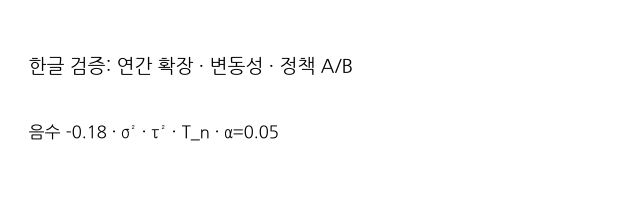

한글 렌더 표본: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1016/R2H_T12_Final/outputs/t12/preflight/한글_폰트_검증.png · SHA256: fe50b3d371a39c68c31f0a8847ad927af88c935afc33114d26f8519618203d49


In [9]:
# 한글·음수·수식 글리프가 실제로 렌더되는지 표본 그림을 만든다.
font_fig, font_ax = plt.subplots(figsize=(8, 2.3))  # 잘림 확인을 위한 실제 캔버스를 만든다.
font_ax.text(.03, .65, "한글 검증: 연간 확장 · 변동성 · 정책 A/B", fontsize=14)  # 핵심 한국어 레이블을 그린다.
font_ax.text(.03, .28, "음수 -0.18 · σ² · τ² · T_n · α=0.05", fontsize=12)  # 수식과 마이너스를 확인한다.
font_ax.set_axis_off()  # 장식 축을 제거한다.
font_path = ROOT / "outputs" / "t12" / "preflight" / "한글_폰트_검증.png"  # 생성 그림을 별도 위치에 저장한다.
font_path.parent.mkdir(parents=True, exist_ok=True)  # 사전 점검 폴더를 만든다.
font_fig.savefig(font_path, dpi=300, bbox_inches="tight")  # 최종 그림과 같은 해상도에서 확인한다.
display(font_fig)  # 제출 노트북 안에도 실제 렌더를 남긴다.
plt.close(font_fig)  # 뒤 셀의 그림 상태를 깨끗하게 유지한다.
print("한글 렌더 표본:", font_path, "· SHA256:", hashlib.sha256(font_path.read_bytes()).hexdigest())  # 그림 출처를 표시한다.

## 사전 점검의 해석

위 실행 출력의 원자료 SHA, 데이터 버전, 20종의 연도 경계와 폰트가 다음 두 노트북의 입력 계약이다. 시세 수정, 환경 버전 차이, 학습일과 검정일의 겹침은 수치 재현을 막는다. 00은 검정 결과를 주장하지 않는다.